In [2]:
from pathlib import Path
import polars as pl

# Since your notebook is inside 'notebooks/', step up one level to the root directory
DATA_DIR = Path("../home-credit-default-risk")
train_path = DATA_DIR / "application_train.csv"

# 1. Scan the CSV lazily
df_train = pl.scan_csv(train_path)

# --- 1. Target Balance Inspection ---
print("--- TARGET BALANCE ---")
target_counts = df_train.select(
    pl.col("TARGET").value_counts(normalize=True) * 100
).collect()
print(target_counts)

# --- 2. Data Structure & Types ---
print("\n--- DATA SHAPE & TYPES ---")
schema = df_train.collect_schema()
print(f"Total Features: {len(schema)}")

# --- 3. Missing Values Summary ---
missing_df = (
    df_train.select(pl.all().is_null().sum())
    .collect()
    .transpose(include_header=True, header_name="column", column_names=["Missing Count"])
)
missing_df = missing_df.with_columns(
    (pl.col("Missing Count") * 100 / df_train.select(pl.len()).collect().item()).alias("Missing %")
)
top_missing = missing_df.filter(pl.col("Missing Count") > 0).sort("Missing %", descending=True).head(10)
print("\n--- TOP 10 COLUMNS WITH HIGHEST MISSING VALUES ---")
print(top_missing)

--- TARGET BALANCE ---
shape: (2, 1)
┌────────────────┐
│ TARGET         │
│ ---            │
│ struct[2]      │
╞════════════════╡
│ {0,91.927118}  │
│ {100,8.072882} │
└────────────────┘

--- DATA SHAPE & TYPES ---
Total Features: 122

--- TOP 10 COLUMNS WITH HIGHEST MISSING VALUES ---
shape: (10, 3)
┌──────────────────────────┬───────────────┬───────────┐
│ column                   ┆ Missing Count ┆ Missing % │
│ ---                      ┆ ---           ┆ ---       │
│ str                      ┆ u32           ┆ f64       │
╞══════════════════════════╪═══════════════╪═══════════╡
│ COMMONAREA_AVG           ┆ 214865        ┆ 69.872297 │
│ COMMONAREA_MODE          ┆ 214865        ┆ 69.872297 │
│ COMMONAREA_MEDI          ┆ 214865        ┆ 69.872297 │
│ NONLIVINGAPARTMENTS_AVG  ┆ 213514        ┆ 69.432963 │
│ NONLIVINGAPARTMENTS_MODE ┆ 213514        ┆ 69.432963 │
│ NONLIVINGAPARTMENTS_MEDI ┆ 213514        ┆ 69.432963 │
│ FONDKAPREMONT_MODE       ┆ 210295        ┆ 68.386172 │
│ LIVINGAPAR

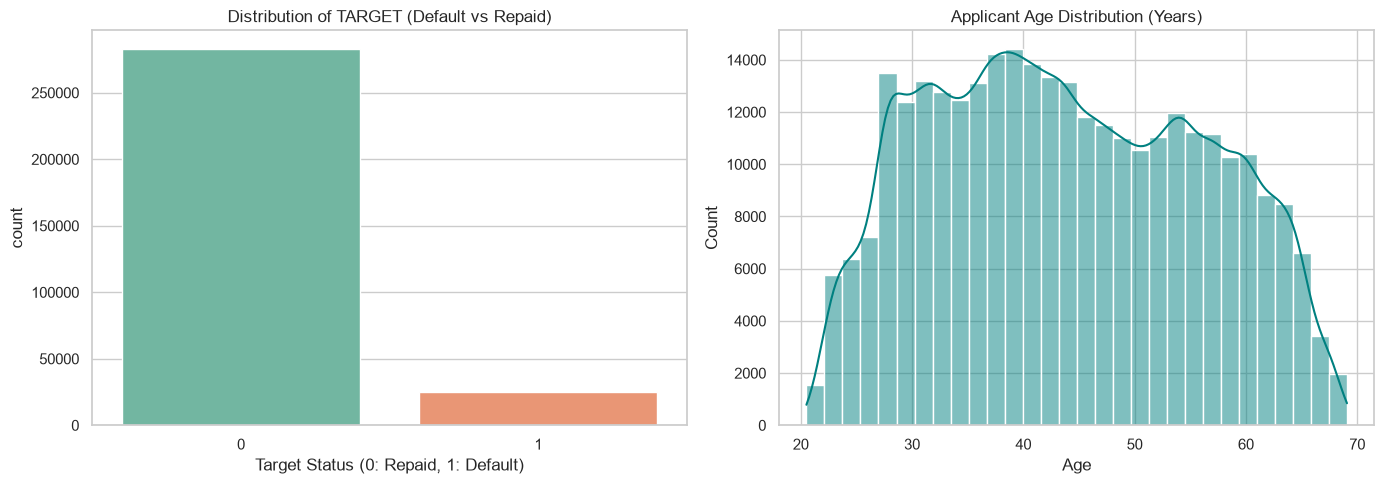

       AMT_INCOME_TOTAL    AMT_CREDIT    AMT_ANNUITY      AGE_YEARS
count      3.075110e+05  3.075110e+05  307499.000000  307511.000000
mean       1.687979e+05  5.990260e+05   27108.573909      43.906900
std        2.371231e+05  4.024908e+05   14493.737315      11.947950
min        2.565000e+04  4.500000e+04    1615.500000      20.503765
25%        1.125000e+05  2.700000e+05   16524.000000      33.984942
50%        1.471500e+05  5.135310e+05   24903.000000      43.121150
75%        2.025000e+05  8.086500e+05   34596.000000      53.886379
max        1.170000e+08  4.050000e+06  258025.500000      69.073238


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Do feature engineering lazily in Polars, then collect & convert to Pandas for Seaborn
df_pd = (
    df_train
    .with_columns(
        (pl.col("DAYS_BIRTH").abs() / 365.25).alias("AGE_YEARS")
    )
    .collect()
    .to_pandas()
)

# 2. Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target Balance
sns.countplot(x='TARGET', hue='TARGET', data=df_pd, ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Distribution of TARGET (Default vs Repaid)')
axes[0].set_xlabel('Target Status (0: Repaid, 1: Default)')

# Plot 2: Age Distribution
sns.histplot(df_pd['AGE_YEARS'], bins=30, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Applicant Age Distribution (Years)')
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()

# --- Statistical Summary for Key Numeric Features ---
key_metrics = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AGE_YEARS']
print(df_pd[key_metrics].describe())